In [1]:
# ============================================================
# Support Vector Machine Example with Open Data and Python
#
# Dataset: scikit-learn's built-in Wine dataset
# Task: Multi-class classification
# Models: Linear SVM and RBF-kernel SVM
# ============================================================

import json
import platform
import zipfile
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import pandas as pd
import sklearn

from sklearn.datasets import load_wine
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC


In [2]:
# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

RANDOM_STATE = 42
TEST_SIZE = 0.20

OUTPUT_DIR = Path("svm_wine_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

generated_files = []


def track_file(path):
    generated_files.append(Path(path))

In [3]:
# ------------------------------------------------------------
# 2. Load the open Wine dataset
# ------------------------------------------------------------

dataset = load_wine(as_frame=True)

X = dataset.data
y = dataset.target
classes = dataset.target_names

print("SUPPORT VECTOR MACHINE EXAMPLE")
print("=" * 50)
print("Dataset shape:", X.shape)
print("Class names:", classes.tolist())

print("\nClass counts:")
print(
    y.value_counts()
    .rename(index=dict(enumerate(classes)))
    .to_string()
)

print("\nFirst five rows:")
print(X.head().to_string())

print("\nDataset description:")
print(dataset.DESCR)


SUPPORT VECTOR MACHINE EXAMPLE
Dataset shape: (178, 13)
Class names: ['class_0', 'class_1', 'class_2']

Class counts:
target
class_1    71
class_0    59
class_2    48

First five rows:
   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  od280/od315_of_diluted_wines  proline
0    14.23        1.71  2.43               15.6      127.0           2.80        3.06                  0.28             2.29             5.64  1.04                          3.92   1065.0
1    13.20        1.78  2.14               11.2      100.0           2.65        2.76                  0.26             1.28             4.38  1.05                          3.40   1050.0
2    13.16        2.36  2.67               18.6      101.0           2.80        3.24                  0.30             2.81             5.68  1.03                          3.17   1185.0
3    14.37        1.95  2.50               16.8      113.0         

In [4]:
# ------------------------------------------------------------
# 3. Create a held-out test set
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,
)

print("\nTraining rows:", len(X_train))
print("Test rows:", len(X_test))




Training rows: 142
Test rows: 36


In [5]:
# ------------------------------------------------------------
# 4. Define two SVM pipelines
# Scaling follows each split's training fold, not the test set.
# ------------------------------------------------------------

linear_svm = Pipeline(
    steps=[
        ("scaler", StandardScaler()),
        (
            "classifier",
            SVC(
                kernel="linear",
                C=1.0,
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)

rbf_svm = Pipeline(
    steps=[
        ("scaler", StandardScaler()),
        (
            "classifier",
            SVC(
                kernel="rbf",
                C=1.0,
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)

base_models = {
    "Linear SVM": linear_svm,
    "RBF SVM": rbf_svm,
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE,
)


In [6]:
# ------------------------------------------------------------
# 5. Compare the two kernel choices
# ------------------------------------------------------------

comparison_rows = []

for model_name, model in base_models.items():
    scores = cross_validate(
        estimator=model,
        X=X_train,
        y=y_train,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "macro_f1": "f1_macro",
        },
        n_jobs=-1,
        error_score="raise",
    )

    comparison_rows.append(
        {
            "model": model_name,
            "cv_accuracy": float(
                scores["test_accuracy"].mean()
            ),
            "cv_accuracy_std": float(
                scores["test_accuracy"].std(ddof=1)
            ),
            "cv_macro_f1": float(
                scores["test_macro_f1"].mean()
            ),
        }
    )

comparison = (
    pd.DataFrame(comparison_rows)
    .sort_values("cv_accuracy", ascending=False)
    .reset_index(drop=True)
)

print("\nCross-validation comparison:")
print(comparison.round(4).to_string(index=False))

comparison_path = OUTPUT_DIR / "kernel_comparison.csv"
comparison.to_csv(comparison_path, index=False)
track_file(comparison_path)


Cross-validation comparison:
     model  cv_accuracy  cv_accuracy_std  cv_macro_f1
Linear SVM       0.9862           0.0308       0.9863
   RBF SVM       0.9862           0.0189       0.9865


In [7]:
# ------------------------------------------------------------
# 6. Tune the better kernel using only the training set
# ------------------------------------------------------------

selected_kernel_name = comparison.iloc[0]["model"]
selected_kernel = "linear" if selected_kernel_name == "Linear SVM" else "rbf"

pipeline = Pipeline(
    steps=[
        ("scaler", StandardScaler()),
        (
            "classifier",
            SVC(
                kernel=selected_kernel,
                probability=True,
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)

if selected_kernel == "linear":
    parameter_grid = {
        "classifier__C": [0.1, 1, 10, 100],
    }
else:
    parameter_grid = {
        "classifier__C": [0.1, 1, 10, 100],
        "classifier__gamma": [
            "scale",
            "auto",
            0.01,
            0.1,
        ],
    }

search = GridSearchCV(
    estimator=pipeline,
    param_grid=parameter_grid,
    scoring="accuracy",
    cv=cv,
    refit=True,
    n_jobs=-1,
    error_score="raise",
    verbose=0,
)

print("\nTuning the selected kernel:", selected_kernel)
search.fit(X_train, y_train)

print("Best CV accuracy:", f"{search.best_score_:.4f}")
print("Best parameters:", search.best_params_)

best_model = search.best_estimator_


Tuning the selected kernel: linear
Best CV accuracy: 0.9862
Best parameters: {'classifier__C': 1}


In [8]:
# ------------------------------------------------------------
# 7. Evaluate once on the held-out test set
# ------------------------------------------------------------

predictions = best_model.predict(X_test)
probabilities = best_model.predict_proba(X_test)

metrics = {
    "algorithm": "Support Vector Classification",
    "selected_kernel": selected_kernel,
    "kernel_selection": (
        "Linear versus RBF compared with training-set "
        "cross-validation"
    ),
    "best_parameters": {
        key: (float(value) if hasattr(value, "item") else value)
        for key, value in search.best_params_.items()
    },
    "note": (
        "probability=True adds Platt-style probability "
        "estimates used for reproducibility; it does not make "
        "predictions guaranteed correct."
    ),
    "test_accuracy": float(
        accuracy_score(y_test, predictions)
    ),
    "test_macro_f1": float(
        f1_score(
            y_test,
            predictions,
            average="macro",
        )
    ),
    "training_samples": int(len(X_train)),
    "test_samples": int(len(X_test)),
}

print("\nHeld-out test results:")
print("Accuracy:", f"{metrics['test_accuracy']:.4f}")
print("Macro F1:", f"{metrics['test_macro_f1']:.4f}")

report = classification_report(
    y_test,
    predictions,
    target_names=classes,
    zero_division=0,
)

print("\nClassification report:")
print(report)

metrics_path = OUTPUT_DIR / "test_metrics.json"

with open(metrics_path, "w") as file:
    json.dump(metrics, file, indent=2)

track_file(metrics_path)

report_path = OUTPUT_DIR / "classification_report.txt"
report_path.write_text(report)
track_file(report_path)


Held-out test results:
Accuracy: 0.9444
Macro F1: 0.9453

Classification report:
              precision    recall  f1-score   support

     class_0       0.92      1.00      0.96        12
     class_1       0.93      0.93      0.93        14
     class_2       1.00      0.90      0.95        10

    accuracy                           0.94        36
   macro avg       0.95      0.94      0.95        36
weighted avg       0.95      0.94      0.94        36



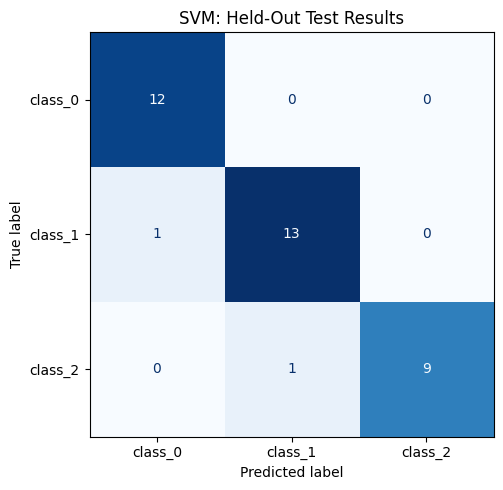

In [9]:
# ------------------------------------------------------------
# 8. Plot the confusion matrix
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    predictions,
    display_labels=classes,
    cmap="Blues",
    colorbar=False,
    ax=ax,
)

ax.set_title("SVM: Held-Out Test Results")
plt.tight_layout()

confusion_path = OUTPUT_DIR / "confusion_matrix.png"
fig.savefig(
    confusion_path,
    dpi=150,
    bbox_inches="tight",
)
track_file(confusion_path)

plt.show()
plt.close(fig)


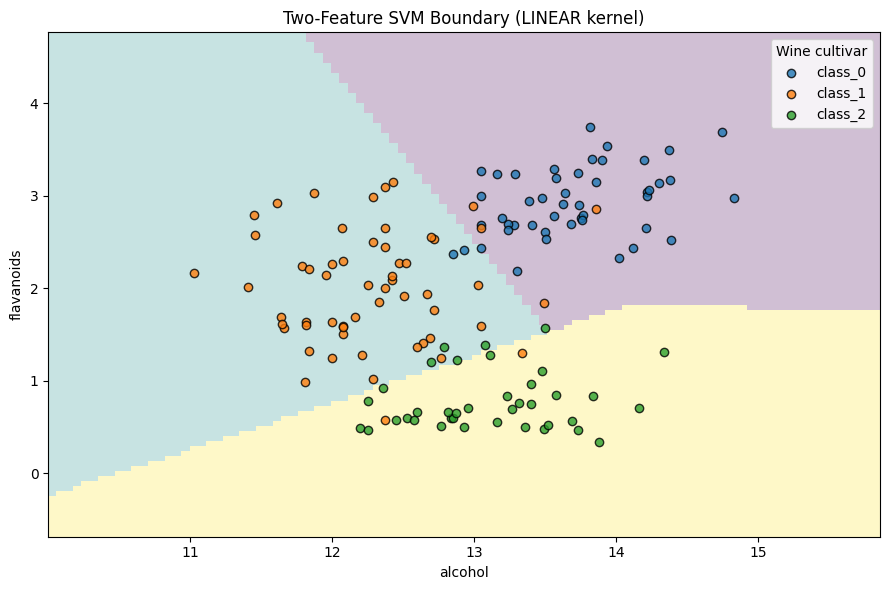

In [10]:
# ------------------------------------------------------------
# 9. Plot a two-feature decision boundary
# This is a separate visualization model, fitted only for
# interpretation using two standardized features.
# ------------------------------------------------------------

feature_x = "alcohol"
feature_y = "flavanoids"

boundary_model = Pipeline(
    steps=[
        ("scaler", StandardScaler()),
        (
            "classifier",
            SVC(
                kernel=selected_kernel,
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)

boundary_data = X_train[[feature_x, feature_y]]
boundary_model.fit(boundary_data, y_train)

fig, ax = plt.subplots(figsize=(9, 6))

DecisionBoundaryDisplay.from_estimator(
    boundary_model,
    boundary_data,
    response_method="predict",
    plot_method="pcolormesh",
    alpha=0.25,
    ax=ax,
)

for class_number, class_name in enumerate(classes):
    mask = y_train == class_number

    ax.scatter(
        boundary_data.loc[mask, feature_x],
        boundary_data.loc[mask, feature_y],
        label=class_name,
        edgecolor="black",
        alpha=0.80,
    )

ax.set_title(
    f"Two-Feature SVM Boundary ({selected_kernel.upper()} kernel)"
)
ax.set_xlabel(feature_x)
ax.set_ylabel(feature_y)
ax.legend(title="Wine cultivar")

plt.tight_layout()

boundary_path = OUTPUT_DIR / "decision_boundary.png"
fig.savefig(
    boundary_path,
    dpi=150,
    bbox_inches="tight",
)
track_file(boundary_path)

plt.show()
plt.close(fig)


In [12]:
# ------------------------------------------------------------
# 10. Save test predictions
# ------------------------------------------------------------

test_results = X_test.copy()

test_results["actual_class"] = y_test
test_results["actual_label"] = [
    classes[value] for value in y_test
]

test_results["predicted_class"] = predictions
test_results["predicted_label"] = [
    classes[value] for value in predictions
]

test_results["highest_predicted_probability"] = (
    probabilities.max(axis=1)
)

test_results["correct"] = (
    test_results["actual_class"]
    == test_results["predicted_class"]
)

predictions_path = OUTPUT_DIR / "test_predictions.csv"

test_results.to_csv(
    predictions_path,
    index_label="original_row_index",
)
track_file(predictions_path)

In [13]:
# ------------------------------------------------------------
# 11. Save the model and metadata
# ------------------------------------------------------------

artifact = {
    "model": best_model,
    "algorithm": "SVC",
    "selected_kernel": selected_kernel,
    "dataset": "sklearn.datasets.load_wine",
    "feature_names": X.columns.tolist(),
    "target_names": classes.tolist(),
    "metrics": metrics,
    "configuration": {
        "random_state": RANDOM_STATE,
        "test_size": TEST_SIZE,
        "cv_folds": 5,
    },
    "versions": {
        "python": platform.python_version(),
        "scikit_learn": sklearn.__version__,
    },
}

model_path = OUTPUT_DIR / "svm_wine_model.joblib"
joblib.dump(artifact, model_path)
track_file(model_path)

print("\nSaved model:", model_path)


Saved model: svm_wine_outputs/svm_wine_model.joblib


In [14]:
# ------------------------------------------------------------
# 12. Reload the model and make one prediction
# Only load model files you trust.
# ------------------------------------------------------------

loaded_artifact = joblib.load(model_path)
loaded_model = loaded_artifact["model"]

sample = X_test.iloc[[0]][
    loaded_artifact["feature_names"]
]

predicted_class = int(loaded_model.predict(sample)[0])
actual_class = int(y_test.iloc[0])

print("\nReloaded-model example:")
print(
    "Actual label:",
    loaded_artifact["target_names"][actual_class],
)
print(
    "Predicted label:",
    loaded_artifact["target_names"][predicted_class],
)



Reloaded-model example:
Actual label: class_0
Predicted label: class_0


In [15]:
# ------------------------------------------------------------
# 13. Package all outputs into one ZIP archive
# ------------------------------------------------------------

zip_path = Path("svm_wine_results.zip")

with zipfile.ZipFile(
    zip_path,
    mode="w",
    compression=zipfile.ZIP_DEFLATED,
) as archive:
    for output_file in generated_files:
        archive.write(
            output_file,
            arcname=output_file.name,
        )

print("\nResults archive:", zip_path)




Results archive: svm_wine_results.zip


In [16]:
# ------------------------------------------------------------
# 14. Download results in Google Colab
# ------------------------------------------------------------

try:
    from google.colab import files
except ImportError:
    print(
        "Not running in Colab. "
        "Results remain in the working directory."
    )
else:
    files.download(str(zip_path))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>